# Task 55: SHAP and LIME Consistency Analysis

Compare both explanations for the same cases with correlation, rank agreement, sign agreement, top-feature overlap, and independent local-surrogate fidelity.

Per-case cross-method agreement and independent verification:


,Pearson signed,Spearman abs-rank,Sign agreement,Top-5 overlap,LIME independent R2,SHAP additivity error
Case,,,,,,
0,0.570,0.643,0.538,0.8,0.959,0.0
15,0.264,0.786,0.385,0.8,0.966,0.0
30,0.160,0.890,0.615,1.0,0.959,0.0
45,0.002,0.868,0.538,0.8,0.931,0.0
60,-0.259,0.549,0.308,0.6,0.963,0.0


Mean Pearson: 0.147 mean Spearman: 0.747 mean sign agreement: 0.477
Feature contribution variability:


,Feature,Mean |SHAP|,SD SHAP,Mean |LIME|,SD LIME
1,sex,0.1386,0.0227,0.1239,0.0043
2,cp,0.1285,0.1153,0.1189,0.0049
8,exang,0.1037,0.0980,0.0897,0.0047
11,ca,0.0957,0.0569,0.1070,0.0107
12,thal,0.0778,0.0125,0.0935,0.0079
9,oldpeak,0.0600,0.0450,0.0747,0.0103
10,slope,0.0492,0.0482,0.0597,0.0035
3,trestbps,0.0468,0.0313,0.0374,0.0016
6,restecg,0.0450,0.0487,0.0484,0.0018
7,thalach,0.0437,0.0624,0.0798,0.0083


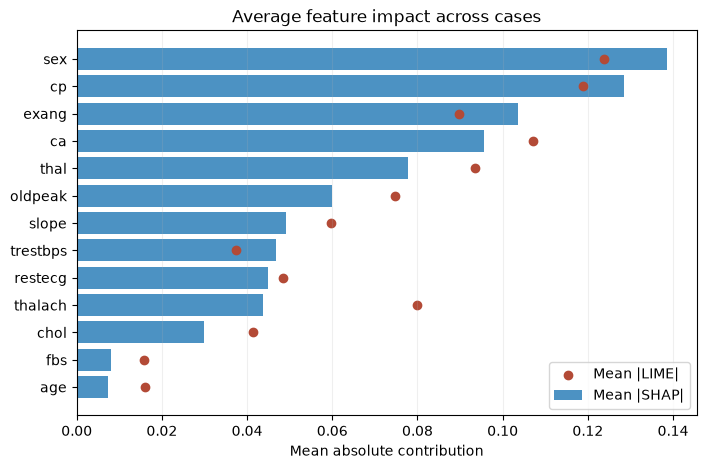

SHAP is additive relative to its empirical background but exact enumeration scales exponentially. LIME is local and cheaper but depends on perturbations and kernel width. Correlated variables and integer-coded categories can make both methods unstable or unrealistic; agreement is not causal validation.


In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_55_SHAP_LIME_Consistency_Analysis/heart.csv'),Path('Heart_Disease_Tasks/Task_55_SHAP_LIME_Consistency_Analysis/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)
def split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
train,test=split(y,.8,55);Xtr,Xte=X[train],X[test];ytr,yte=y[train],y[test]
mean,scale=Xtr.mean(0),Xtr.std(0);scale[scale==0]=1;Xtr,Xte=(Xtr-mean)/scale,(Xte-mean)/scale
class Logistic:
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1200):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y;self.w-=.06*(x.T@e/len(y)+.02*self.w);self.b-=.06*e.mean()
        return self
    def proba(self,x):return 1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))
model=Logistic().fit(Xtr,ytr)
background=Xtr[np.linspace(0,len(Xtr)-1,min(6,len(Xtr)),dtype=int)]

def shapley(instance):
    p=len(instance);coalitions=np.arange(1<<p,dtype=np.int64);bits=1<<np.arange(p);mask=(coalitions[:,None]&bits[None,:])!=0;values=np.empty(len(coalitions))
    for start in range(0,len(coalitions),128):
        stop=min(start+128,len(coalitions));hybrid=np.where(mask[start:stop,None,:],instance[None,None,:],background[None,:,:])
        values[start:stop]=model.proba(hybrid.reshape(-1,p)).reshape(stop-start,len(background)).mean(1)
    phi=np.zeros(p);factorial=math.factorial;denom=factorial(p)
    for j in range(p):
        bit=1<<j;eligible=coalitions[(coalitions&bit)==0]
        for subset in eligible:
            k=int(subset).bit_count();phi[j]+=factorial(k)*factorial(p-k-1)/denom*(values[subset|bit]-values[subset])
    return float(values[0]),phi

def lime(instance,seed,count=900,width=.75):
    rng=np.random.default_rng(seed);ids=rng.integers(0,len(Xtr),size=(count,len(instance)))
    samples=Xtr[ids,np.arange(len(instance))[None,:]];samples[0]=instance
    distance=np.sqrt(np.mean((samples-instance)**2,axis=1));weights=np.exp(-(distance**2)/(width**2));target=model.proba(samples)
    design=np.column_stack([np.ones(len(samples)),samples]);root=np.sqrt(weights);weighted=design*root[:,None]
    penalty=np.eye(design.shape[1])*.01;penalty[0,0]=0
    beta=np.linalg.solve(weighted.T@weighted+penalty,weighted.T@(target*root))
    return beta[0],beta[1:]

def ranks(values):
    order=np.argsort(values,kind='stable');result=np.empty(len(values),float);start=0
    while start<len(order):
        stop=start+1
        while stop<len(order) and values[order[stop]]==values[order[start]]:stop+=1
        result[order[start:stop]]=(start+stop-1)/2+1;start=stop
    return result
def corr(a,b):
    return float(np.corrcoef(a,b)[0,1]) if np.std(a)>1e-12 and np.std(b)>1e-12 else 0.
def weighted_r2(actual,pred,weights):
    avg=np.average(actual,weights=weights);res=np.sum(weights*(actual-pred)**2);tot=np.sum(weights*(actual-avg)**2)
    return 1-res/tot if tot>1e-12 else 1.

case_ids=np.linspace(0,len(Xte)-1,min(5,len(Xte)),dtype=int);shap_values=[];lime_values=[];rows=[];fidelity=[]
for number,index in enumerate(case_ids):
    instance=Xte[index];base,sv=shapley(instance);intercept,lv=lime(instance,7000+number)
    verification_rng=np.random.default_rng(8000+number);ids=verification_rng.integers(0,len(Xtr),size=(400,len(instance)))
    verification=Xtr[ids,np.arange(len(instance))[None,:]];distance=np.sqrt(np.mean((verification-instance)**2,axis=1));weights=np.exp(-(distance**2)/(.75**2))
    fidelity.append(weighted_r2(model.proba(verification),intercept+verification@lv,weights))
    shap_values.append(sv);lime_values.append(lv)
    sr,lr=ranks(np.abs(sv)),ranks(np.abs(lv));top=min(5,len(features))
    top_s=set(np.argsort(np.abs(sv))[-top:]);top_l=set(np.argsort(np.abs(lv))[-top:])
    rows.append({'Case':int(index),'Pearson signed':corr(sv,lv),'Spearman abs-rank':corr(sr,lr),'Sign agreement':float(np.mean(np.sign(sv)==np.sign(lv))),'Top-5 overlap':len(top_s&top_l)/top,'LIME independent R2':fidelity[-1],'SHAP additivity error':abs(base+sv.sum()-model.proba(instance[None,:])[0])})
shap_values,lime_values=np.asarray(shap_values),np.asarray(lime_values)
comparison=pd.DataFrame(rows).set_index('Case');print('Per-case cross-method agreement and independent verification:');display(comparison.round(3))
print('Mean Pearson:',round(comparison['Pearson signed'].mean(),3),'mean Spearman:',round(comparison['Spearman abs-rank'].mean(),3),'mean sign agreement:',round(comparison['Sign agreement'].mean(),3))
variability=pd.DataFrame({'Feature':features,'Mean |SHAP|':np.mean(np.abs(shap_values),axis=0),'SD SHAP':np.std(shap_values,axis=0),'Mean |LIME|':np.mean(np.abs(lime_values),axis=0),'SD LIME':np.std(lime_values,axis=0)}).sort_values('Mean |SHAP|',ascending=False)
print('Feature contribution variability:');display(variability.round(4))
fig,ax=plt.subplots(figsize=(8,5));ordered=np.argsort(variability['Mean |SHAP|'].to_numpy())
ax.barh(variability['Feature'].to_numpy()[ordered],variability['Mean |SHAP|'].to_numpy()[ordered],label='Mean |SHAP|',alpha=.8)
ax.scatter(variability['Mean |LIME|'].to_numpy()[ordered],variability['Feature'].to_numpy()[ordered],color='#b34a36',label='Mean |LIME|')
ax.set_xlabel('Mean absolute contribution');ax.set_title('Average feature impact across cases');ax.legend();ax.grid(axis='x',alpha=.2);plt.show()
print('SHAP is additive relative to its empirical background but exact enumeration scales exponentially. LIME is local and cheaper but depends on perturbations and kernel width. Correlated variables and integer-coded categories can make both methods unstable or unrealistic; agreement is not causal validation.')